# Why every model confuses youtube for google, and what to do about it

In [1]:
# %pip install imblearn

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix, roc_auc_score
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.ensemble import HistGradientBoostingClassifier

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler

random_state = 42

In [3]:
training_data = pd.read_csv("../dataset/task1_static/train_features.csv")
training_labels = pd.read_csv("../dataset/task1_static/train_labels.csv")
training_data = training_data.merge(training_labels, left_on="flow_id", right_on="flow_id")

validation_data = pd.read_csv("../dataset/task1_static/validation_features.csv")
validation_labels = pd.read_csv("../dataset/task1_static/validation_labels.csv")
validation_data = validation_data.merge(validation_labels, left_on="flow_id", right_on="flow_id")

print(training_data["app"].value_counts())
print("\nShare of training rows:")
print((training_data["app"].value_counts(normalize=True) * 100).round(1))

app
google       98
x            55
youtube      41
mozilla      31
instagram    14
facebook      8
Name: count, dtype: int64

Share of training rows:
app
google       39.7
x            22.3
youtube      16.6
mozilla      12.6
instagram     5.7
facebook      3.2
Name: proportion, dtype: float64


In [4]:
selected_features = ['transport', 'start_rel', 'duration', 'server_port', 'packet_count_down', 'bytes_up', 'mean_pkt_size_up', 'mean_pkt_size_down',
                     'std_pkt_size_up', 'std_pkt_size_down', 'mean_iat', 'std_iat', 'min_iat', 'max_iat', 'up_down_packet_ratio', 'up_down_byte_ratio']

X_train = training_data[selected_features].copy()
y_train = training_data["app"].copy()
X_val = validation_data[selected_features].copy()
y_val = validation_data["app"].copy()

def preprocess_data(X):
    numeric = X.select_dtypes(include=np.number).columns.tolist()
    categorical = X.select_dtypes(exclude=np.number).columns.tolist()
    numeric_pipe = Pipeline([('scaler', StandardScaler())])
    categorical_pipe = Pipeline([('onehot', OneHotEncoder(handle_unknown='ignore'))])
    return ColumnTransformer([('numeric', numeric_pipe, numeric),
                              ('categorical', categorical_pipe, categorical)])

## 1. Is google vs. youtube actually separable in these features?

Every feature-association number in the EDA notebook (`transport` 0.73, `std_pkt_size_up` 0.376, etc.) is averaged across all 6
classes. That hides whether a feature separates *this specific pair*. Here we isolate the google/youtube rows and compute a
direction-agnostic AUC per numeric feature — 0.5 means the feature can't tell the two classes apart at all, 1.0 means perfect
separation.

In [5]:
pair_df = training_data[training_data["app"].isin(["google", "youtube"])].copy()
print(pair_df["app"].value_counts())

y_pair = (pair_df["app"] == "youtube").astype(int)  # 1 = youtube, 0 = google
numeric_cols = pair_df.select_dtypes(include=np.number).columns.tolist()

rows = []
for col in numeric_cols:
    vals = pair_df[col]
    if vals.nunique() <= 1:
        continue
    auc = roc_auc_score(y_pair, vals)
    auc = max(auc, 1 - auc)  # direction doesn't matter, only separability
    rows.append({"feature": col, "google_vs_youtube_auc": auc})

pairwise_auc_df = pd.DataFrame(rows).sort_values("google_vs_youtube_auc", ascending=False).reset_index(drop=True)
print(pairwise_auc_df)
pairwise_auc_df.to_csv("google_youtube_pairwise_auc.csv", index=False)

# transport is categorical: just look at the raw split
print("\ntransport counts within google/youtube only:")
print(pd.crosstab(pair_df["transport"], pair_df["app"]))

app
google     98
youtube    41
Name: count, dtype: int64
                 feature  google_vs_youtube_auc
0       mean_pkt_size_up               0.715032
1     up_down_byte_ratio               0.696615
2     mean_pkt_size_down               0.636635
3              start_rel               0.606023
4               bytes_up               0.603285
5        std_pkt_size_up               0.575660
6             bytes_down               0.575411
7   up_down_packet_ratio               0.552265
8            burst_count               0.545545
9      packet_count_down               0.526755
10               max_iat               0.520035
11              duration               0.518666
12       packet_count_up               0.515306
13               min_iat               0.507218
14     std_pkt_size_down               0.506720
15              mean_iat               0.504978
16               std_iat               0.501493

transport counts within google/youtube only:
app        google  youtube
trans

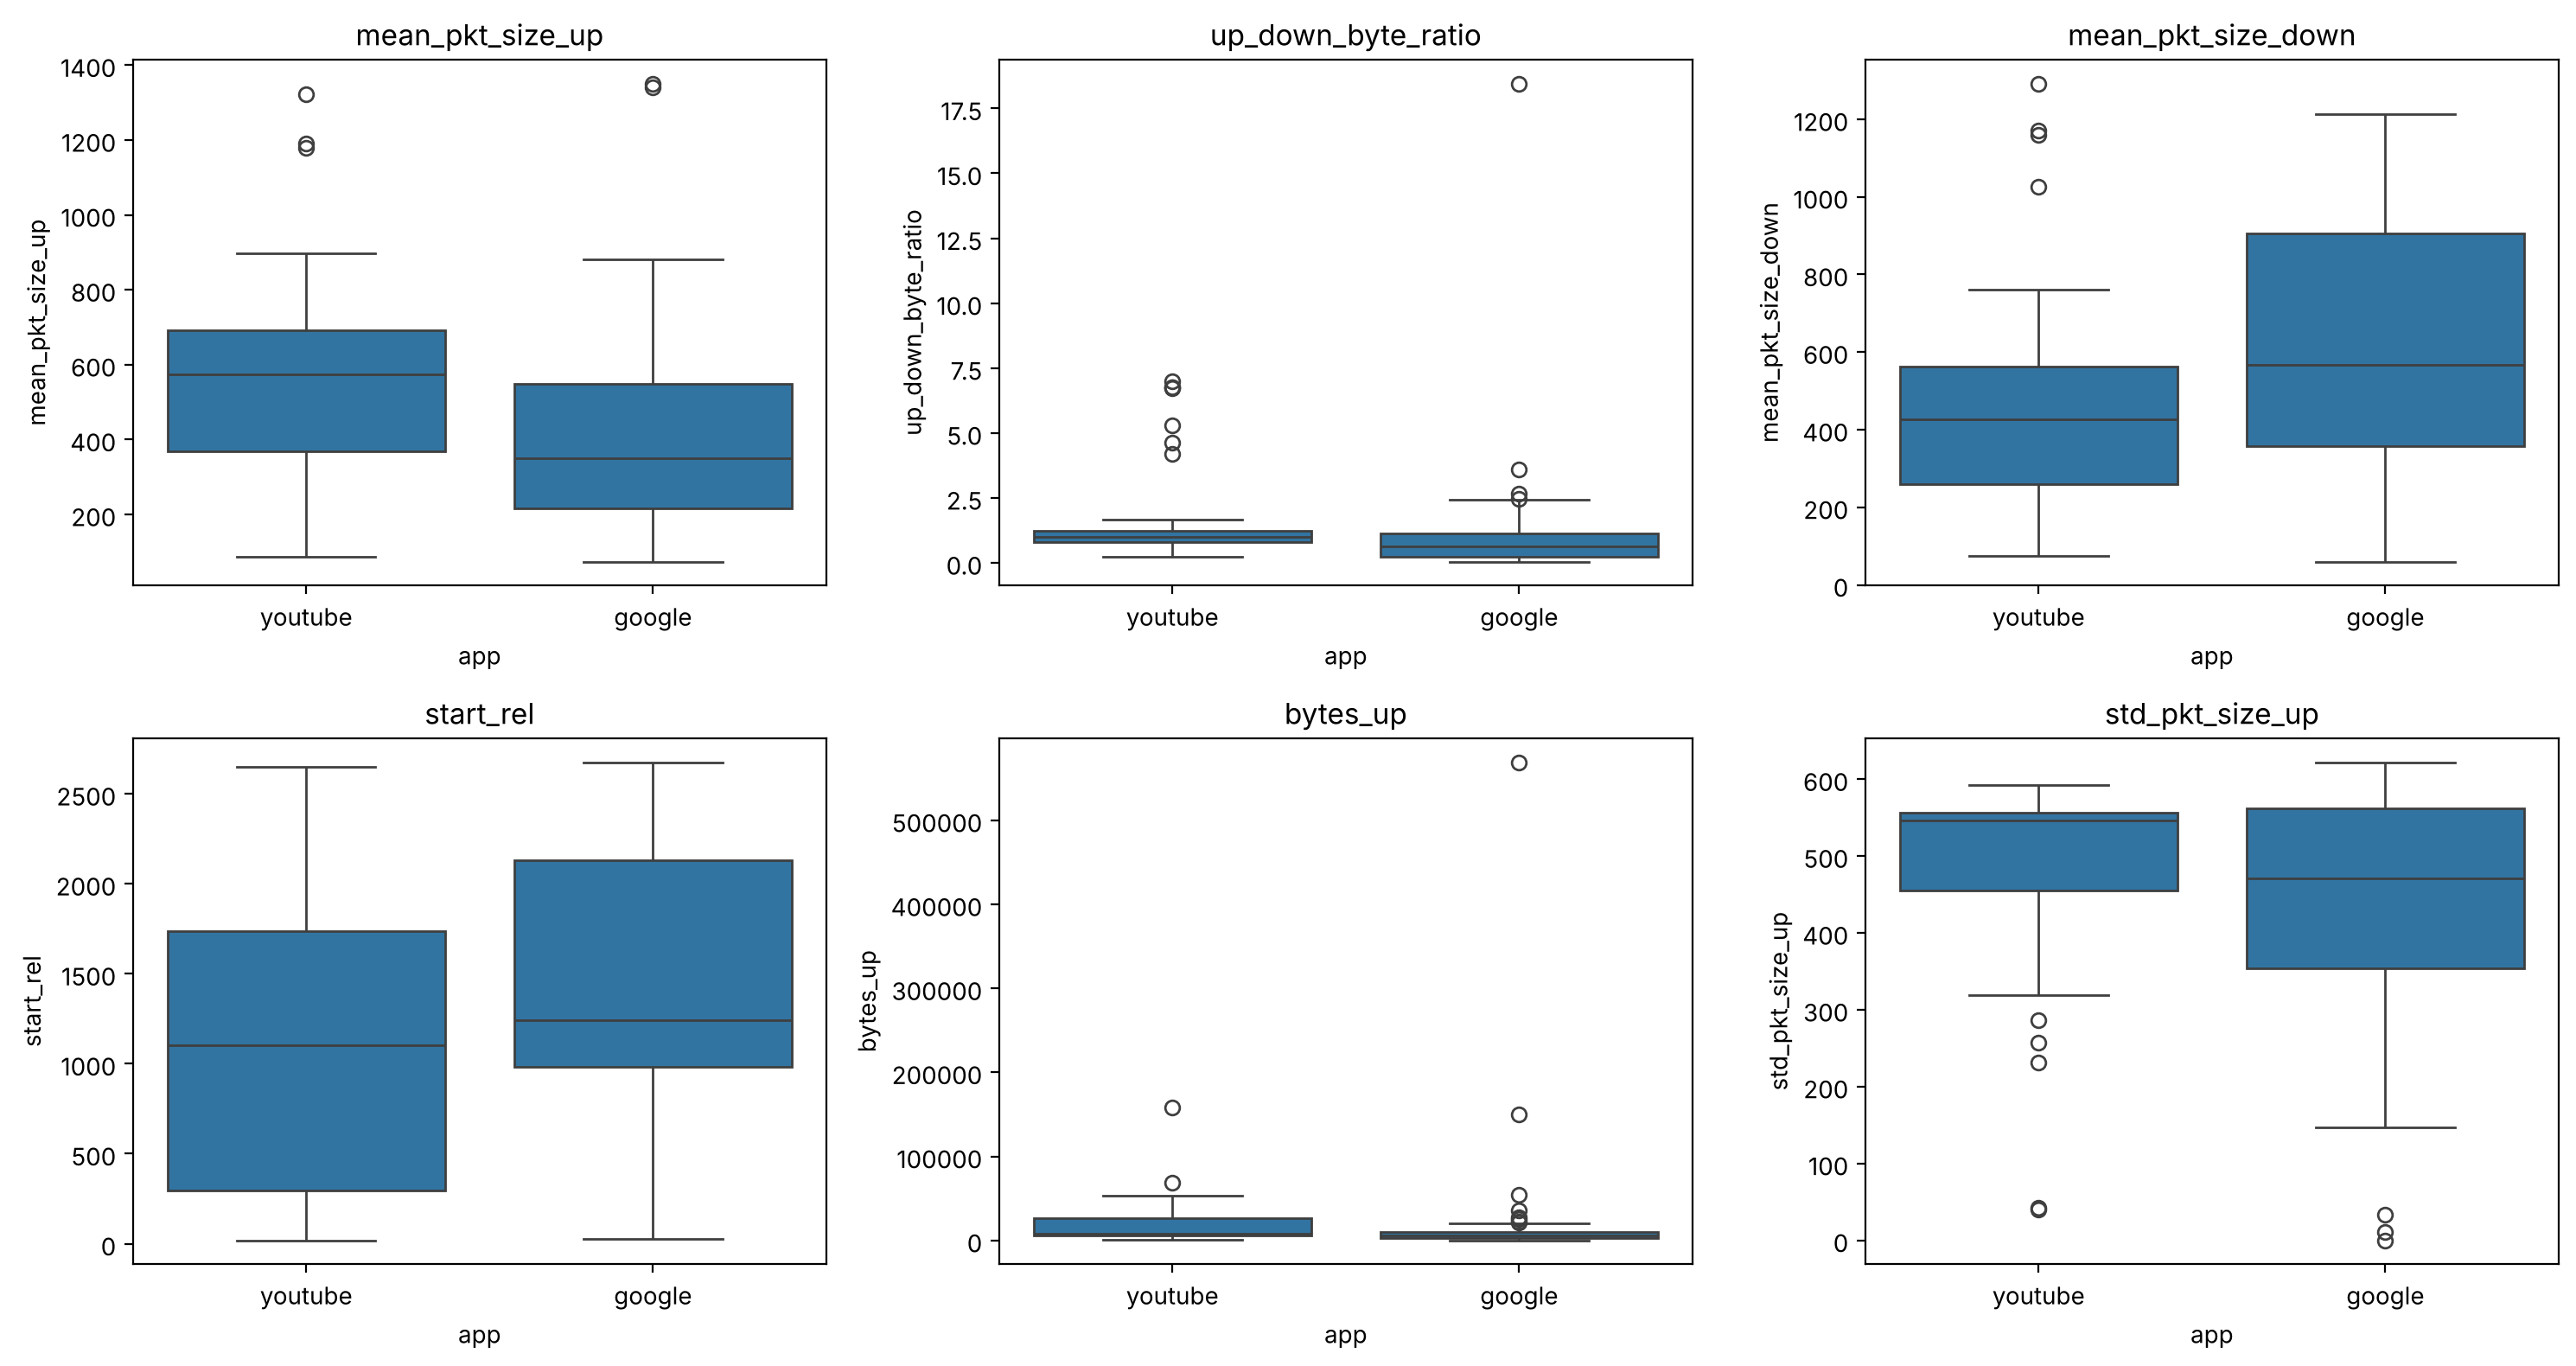

In [6]:
top_features = pairwise_auc_df["feature"].head(6).tolist()

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, feat in zip(axes.flat, top_features):
    sns.boxplot(data=pair_df, x="app", y=feat, ax=ax)
    ax.set_title(feat)
plt.tight_layout()
plt.show()

## 2. Engineer a feature that targets *why* they'd overlap

YouTube is sustained video download; typical Google traffic (search, APIs) is short request/response — even riding the same
infrastructure, the *rate* of downstream data should differ more than its raw packet-size/IAT statistics. Add throughput-style
features built from what survived the correlation filter (`packet_count_down`, `mean_pkt_size_down`, `duration`) and re-run the
same pairwise AUC check to see whether they outrank the original features for this specific pair.

In [7]:
def add_rate_features(df):
    df = df.copy()
    eps = 1e-6
    df["down_packet_rate"] = df["packet_count_down"] / (df["duration"] + eps)
    df["down_byte_rate_est"] = (df["packet_count_down"] * df["mean_pkt_size_down"]) / (df["duration"] + eps)
    df["up_down_pkt_size_ratio"] = df["mean_pkt_size_up"] / (df["mean_pkt_size_down"] + eps)
    return df

training_data_fe = add_rate_features(training_data)
validation_data_fe = add_rate_features(validation_data)

engineered_features = ["down_packet_rate", "down_byte_rate_est", "up_down_pkt_size_ratio"]

pair_df_fe = training_data_fe[training_data_fe["app"].isin(["google", "youtube"])].copy()
y_pair_fe = (pair_df_fe["app"] == "youtube").astype(int)

rows = []
for col in numeric_cols + engineered_features:
    vals = pair_df_fe[col]
    if vals.nunique() <= 1:
        continue
    auc = roc_auc_score(y_pair_fe, vals)
    auc = max(auc, 1 - auc)
    rows.append({"feature": col, "google_vs_youtube_auc": auc})

pairwise_auc_fe_df = pd.DataFrame(rows).sort_values("google_vs_youtube_auc", ascending=False).reset_index(drop=True)
print(pairwise_auc_fe_df)

                   feature  google_vs_youtube_auc
0         mean_pkt_size_up               0.715032
1       up_down_byte_ratio               0.696615
2   up_down_pkt_size_ratio               0.692135
3       mean_pkt_size_down               0.636635
4                start_rel               0.606023
5                 bytes_up               0.603285
6          std_pkt_size_up               0.575660
7               bytes_down               0.575411
8     up_down_packet_ratio               0.552265
9              burst_count               0.545545
10      down_byte_rate_est               0.536088
11       packet_count_down               0.526755
12                 max_iat               0.520035
13                duration               0.518666
14         packet_count_up               0.515306
15                 min_iat               0.507218
16       std_pkt_size_down               0.506720
17                mean_iat               0.504978
18        down_packet_rate               0.503484


## 3. Does fixing the imbalance / adding the features actually move macro-F1?

Four runs of the same model (`HistGradientBoostingClassifier`, swap in whatever your best model from the other notebooks is) on
the same train/validation split:

- **Baseline** — original 16 features, no class weighting (what you already have).
- **+ engineered features** — original 16 + the 3 throughput features above.
- **+ class weighting** — engineered features, with `sample_weight` from `compute_sample_weight('balanced', y_train)` so the
  model is penalized more for misclassifying minority classes instead of leaving that to chance in `GridSearchCV`.
- **+ oversampling** — engineered features, with `RandomOverSampler` inside an `imblearn` pipeline so minority classes
  (youtube, instagram, facebook) are resampled up to the majority count *only within the training fold* (never touches
  validation data, so there's no leakage).

Each run prints overall macro-F1 plus youtube's own recall/F1 and google's precision, so you can see directly whether the
google→youtube leak narrows.


Baseline (16 features, unweighted)
Macro-F1:         0.7079182630906767
Accuracy:         0.8433734939759037
Youtube recall:   0.7857142857142857
Youtube F1:       0.7586206896551724
Google precision: 0.8378378378378378


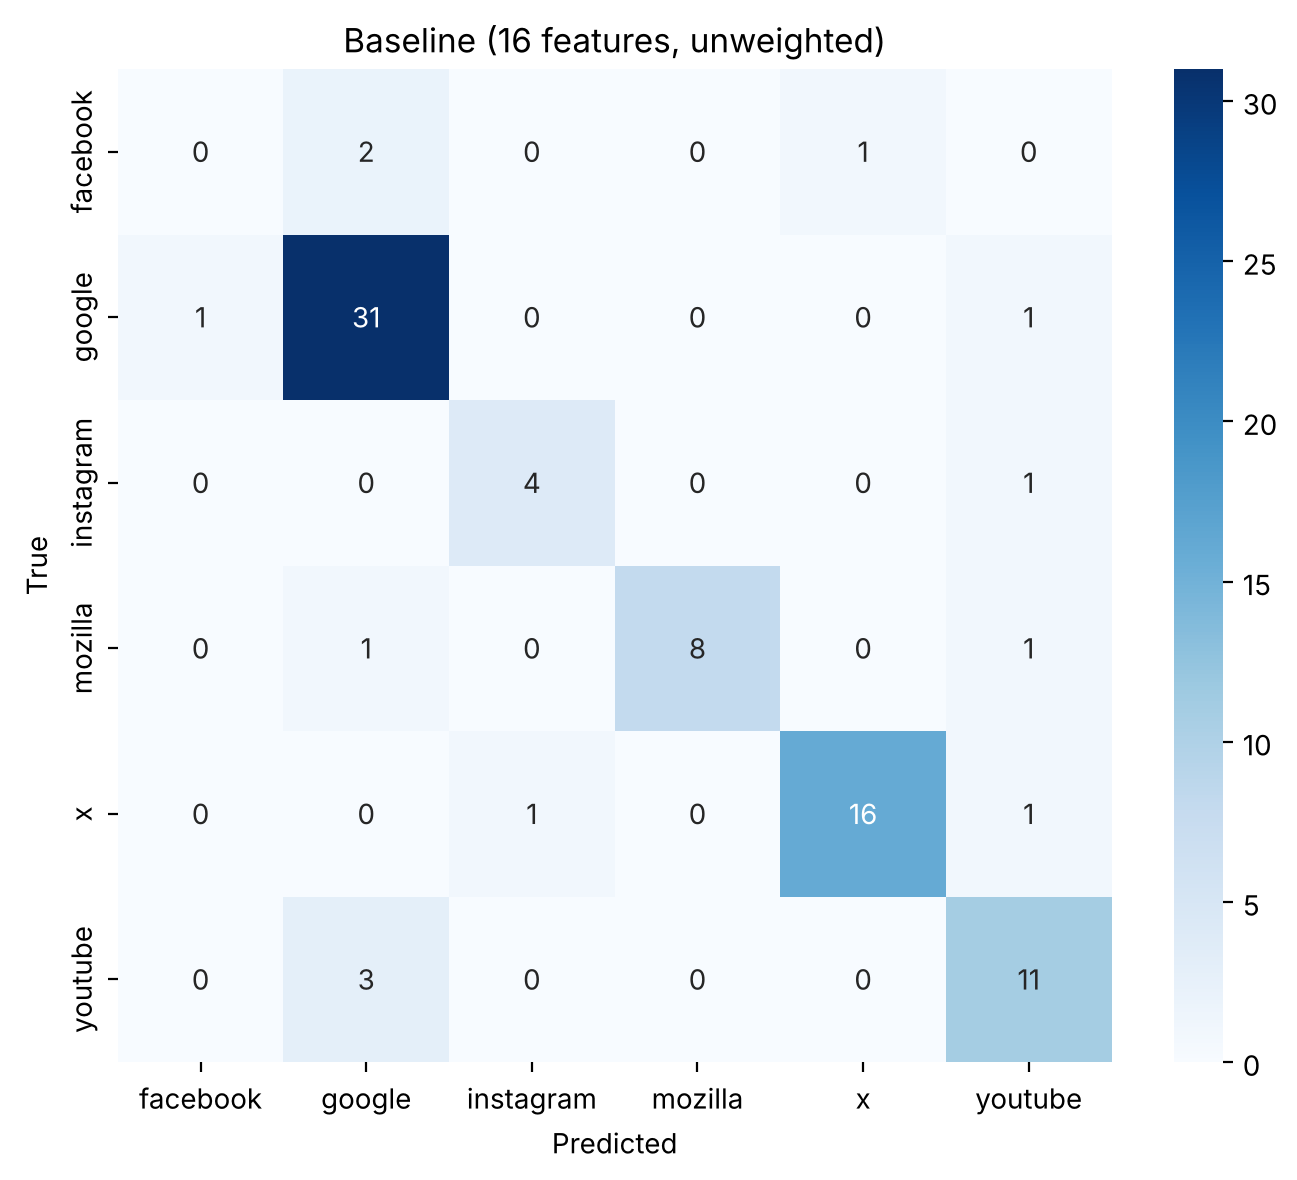


+ engineered throughput features
Macro-F1:         0.68796992481203
Accuracy:         0.8192771084337349
Youtube recall:   0.7142857142857143
Youtube F1:       0.7142857142857143
Google precision: 0.8108108108108109


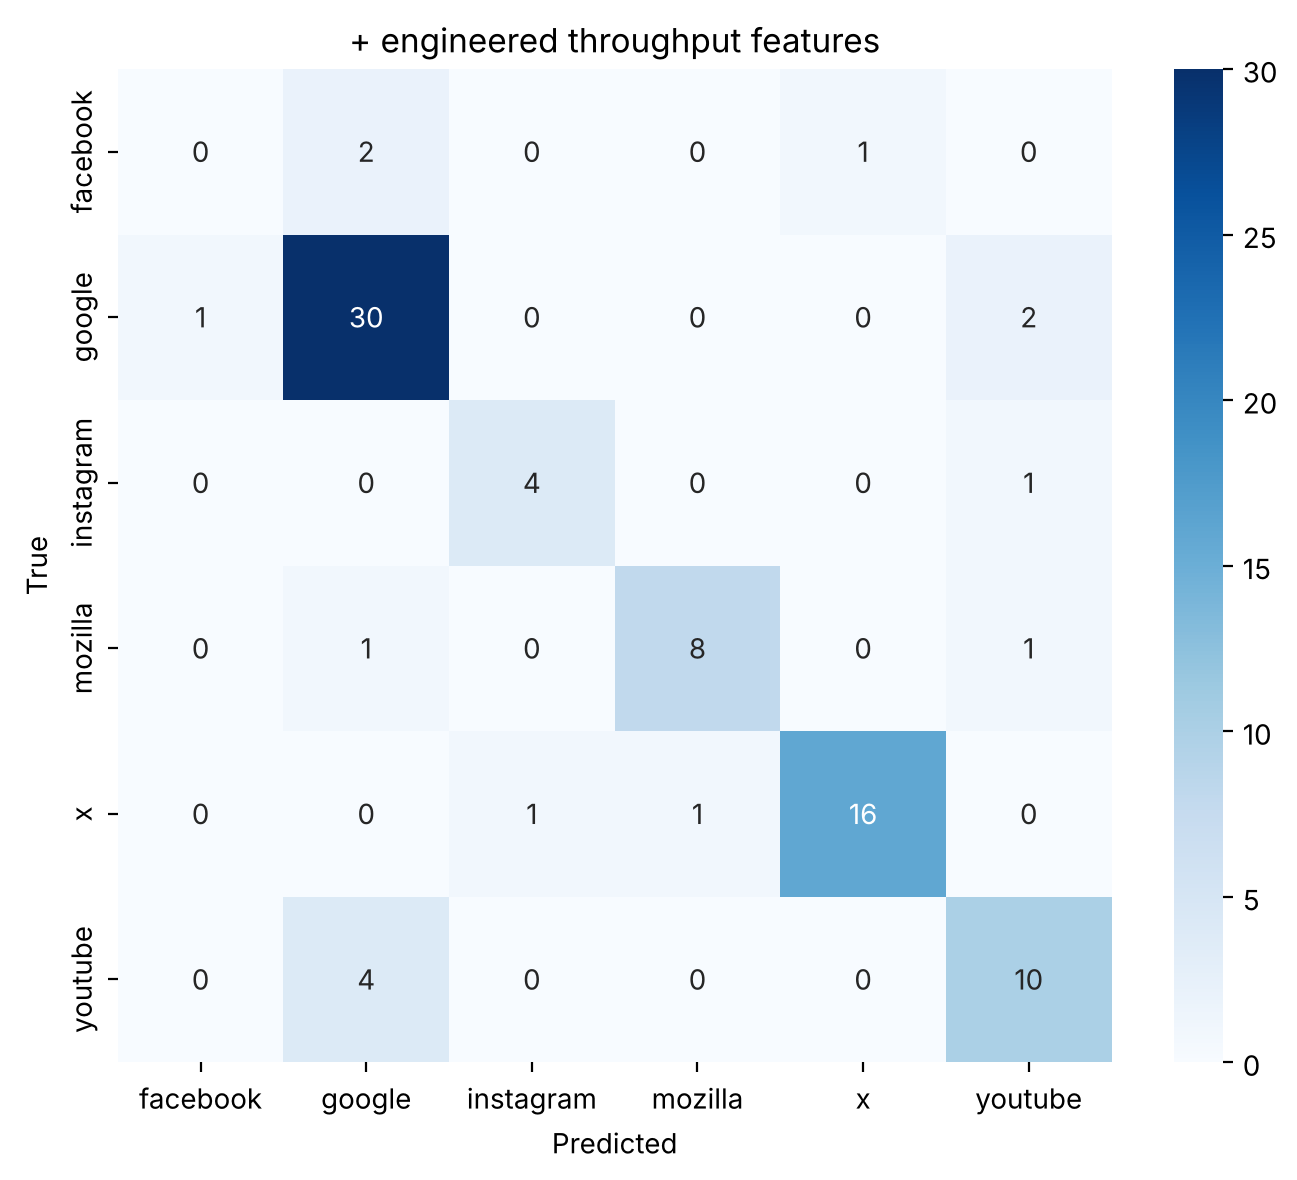


+ engineered features + balanced class weighting
Macro-F1:         0.7321272953625896
Accuracy:         0.8192771084337349
Youtube recall:   0.7857142857142857
Youtube F1:       0.7333333333333333
Google precision: 0.8108108108108109


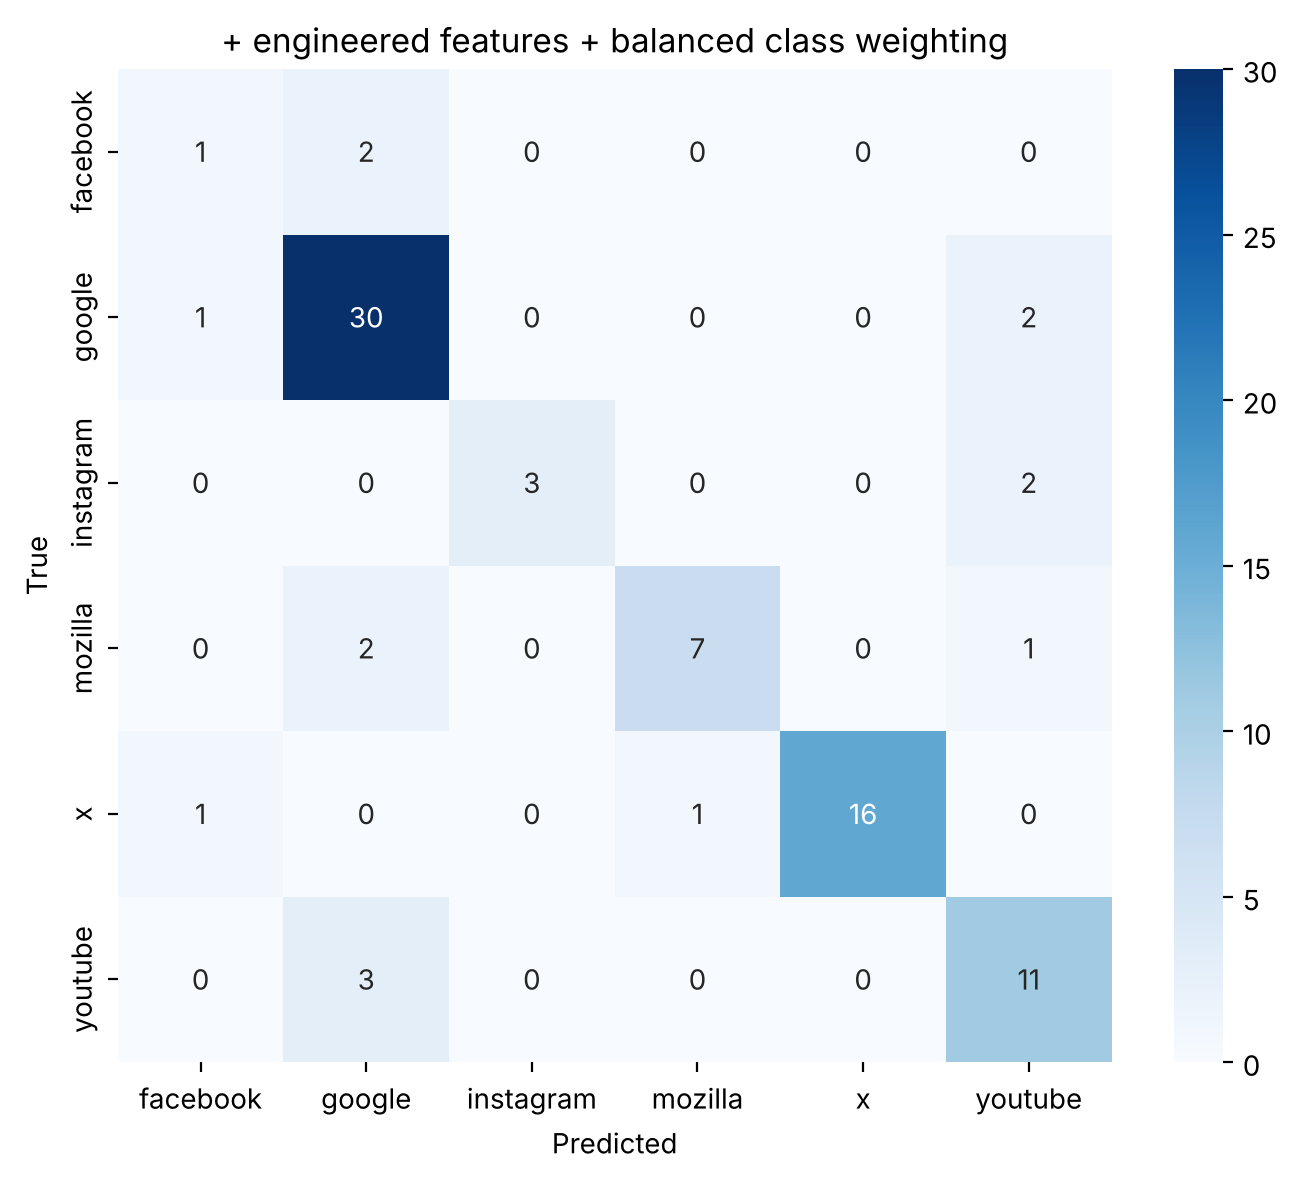


+ engineered features + random oversampling
Macro-F1:         0.7550494593972855
Accuracy:         0.8313253012048193
Youtube recall:   0.6428571428571429
Youtube F1:       0.6666666666666666
Google precision: 0.8611111111111112


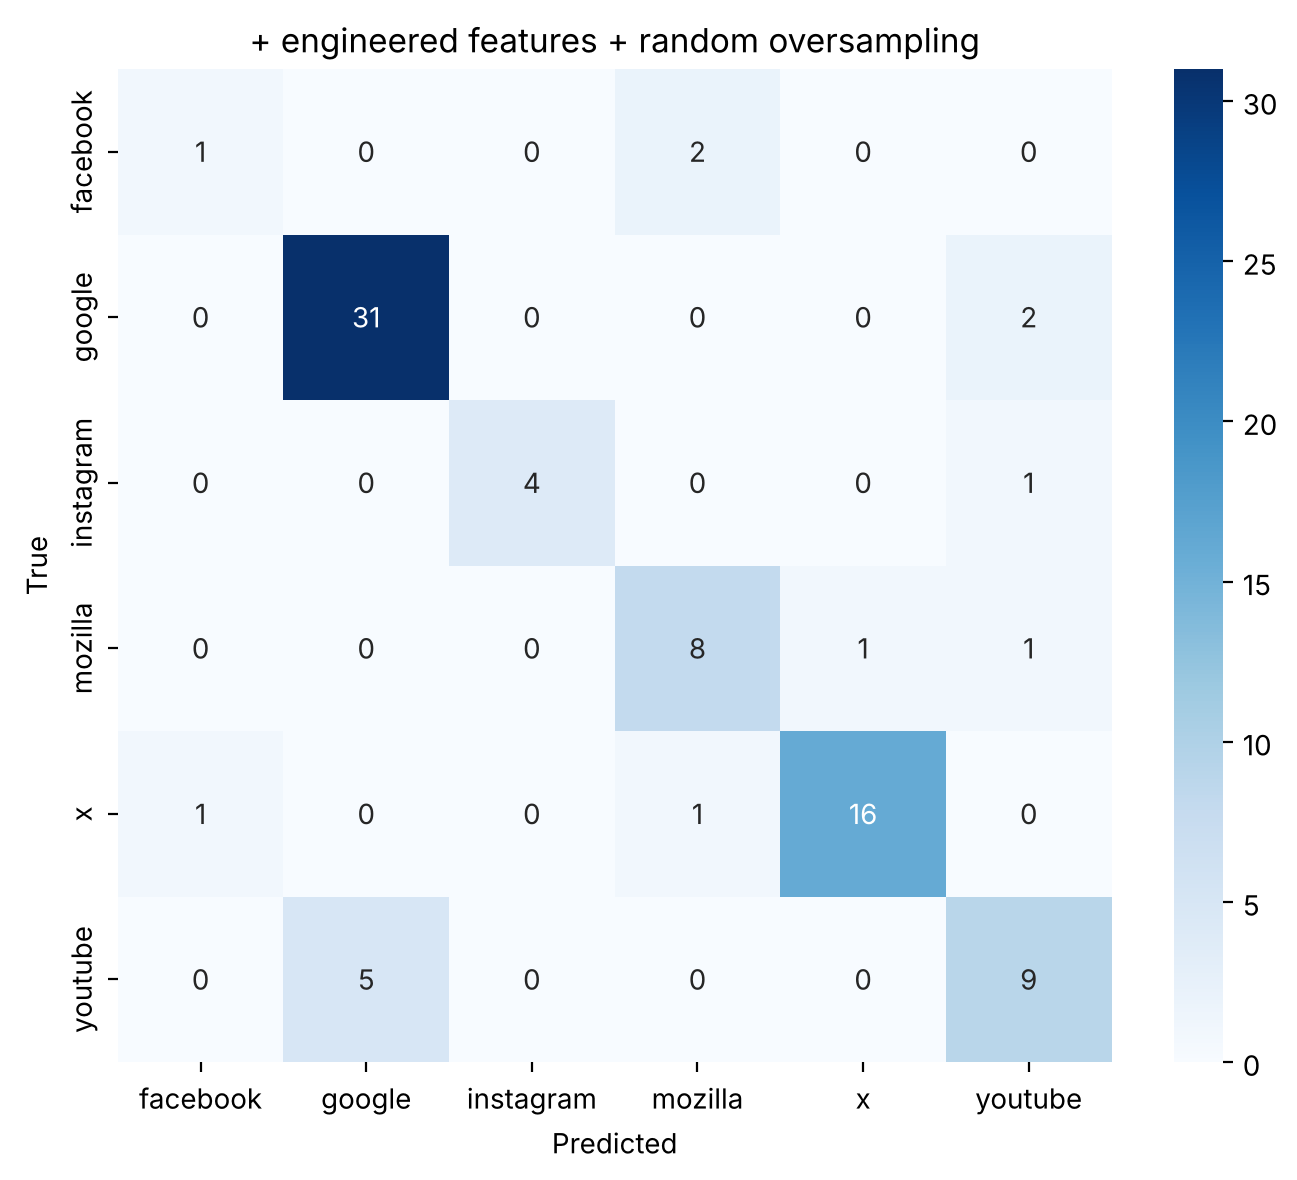

,Run,Macro_F1,Youtube_Recall
0,Baseline,0.707918,0.785714
1,+ engineered features,0.687970,0.714286
2,+ class weighting,0.732127,0.785714
3,+ oversampling,0.755049,0.642857


In [8]:
def summarize(yte, pred, label):
    report = classification_report(yte, pred, output_dict=True, zero_division=0)
    print(f"\n{label}")
    print("Macro-F1:        ", f1_score(yte, pred, average='macro'))
    print("Accuracy:        ", accuracy_score(yte, pred))
    print("Youtube recall:  ", report.get('youtube', {}).get('recall'))
    print("Youtube F1:      ", report.get('youtube', {}).get('f1-score'))
    print("Google precision:", report.get('google', {}).get('precision'))
    labels = sorted(yte.unique())
    cm = confusion_matrix(yte, pred, labels=labels)
    plt.figure(figsize=(7, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
    plt.xlabel('Predicted'); plt.ylabel('True'); plt.title(label)
    plt.tight_layout(); plt.show()
    return report

results_summary = []

# --- Baseline: original 16 features, no weighting ---
pipe_base = Pipeline([('preprocess', preprocess_data(X_train)), ('model', HistGradientBoostingClassifier(random_state=random_state))])
pipe_base.fit(X_train, y_train)
pred_base = pipe_base.predict(X_val)
r = summarize(y_val, pred_base, "Baseline (16 features, unweighted)")
results_summary.append(("Baseline", f1_score(y_val, pred_base, average='macro'), r.get('youtube', {}).get('recall')))

# --- + engineered features ---
extended_features = selected_features + engineered_features
Xtr_fe = training_data_fe[extended_features].copy()
Xte_fe = validation_data_fe[extended_features].copy()

pipe_fe = Pipeline([('preprocess', preprocess_data(Xtr_fe)), ('model', HistGradientBoostingClassifier(random_state=random_state))])
pipe_fe.fit(Xtr_fe, y_train)
pred_fe = pipe_fe.predict(Xte_fe)
r = summarize(y_val, pred_fe, "+ engineered throughput features")
results_summary.append(("+ engineered features", f1_score(y_val, pred_fe, average='macro'), r.get('youtube', {}).get('recall')))

# --- + class weighting ---
sample_weight = compute_sample_weight('balanced', y_train)
pipe_w = Pipeline([('preprocess', preprocess_data(Xtr_fe)), ('model', HistGradientBoostingClassifier(random_state=random_state))])
pipe_w.fit(Xtr_fe, y_train, model__sample_weight=sample_weight)
pred_w = pipe_w.predict(Xte_fe)
r = summarize(y_val, pred_w, "+ engineered features + balanced class weighting")
results_summary.append(("+ class weighting", f1_score(y_val, pred_w, average='macro'), r.get('youtube', {}).get('recall')))

# --- + oversampling (train-fold only, via imblearn pipeline) ---
pipe_os = ImbPipeline([
    ('preprocess', preprocess_data(Xtr_fe)),
    ('oversample', RandomOverSampler(random_state=random_state)),
    ('model', HistGradientBoostingClassifier(random_state=random_state)),
])
pipe_os.fit(Xtr_fe, y_train)
pred_os = pipe_os.predict(Xte_fe)
r = summarize(y_val, pred_os, "+ engineered features + random oversampling")
results_summary.append(("+ oversampling", f1_score(y_val, pred_os, average='macro'), r.get('youtube', {}).get('recall')))

summary_df = pd.DataFrame(results_summary, columns=["Run", "Macro_F1", "Youtube_Recall"])
display(summary_df)
summary_df.to_csv("google_youtube_remedy_comparison.csv", index=False)

## 4. How much of the error is actually google <-> youtube?

The confusion matrices of the 7 tuned models all show the same google/youtube block. To put a number on it, refit
each model with its best E1 parameters (copied from notebooks 01-07) on the 16 features and count the swaps.

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, AdaBoostClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.preprocessing import FunctionTransformer

# best E1 parameters from the respective notebooks
best_models = {
    'LR': LogisticRegression(C=100, class_weight='balanced', solver='lbfgs', max_iter=3000, random_state=random_state),
    'KNN': KNeighborsClassifier(n_neighbors=3, p=1, weights='distance'),
    'SVM': SVC(C=100, kernel='rbf', gamma='scale', probability=True, random_state=random_state),
    '1-DT': DecisionTreeClassifier(criterion='gini', max_depth=15, class_weight='balanced', random_state=random_state),
    'Bagged-DT': BaggingClassifier(estimator=DecisionTreeClassifier(max_depth=15, random_state=random_state),
                                   n_estimators=50, max_samples=0.5, max_features=0.75, random_state=random_state),
    'Boosting-DT': HistGradientBoostingClassifier(learning_rate=0.2, max_iter=50, max_leaf_nodes=15,
                                                  l2_regularization=1.0, random_state=random_state),
    'AdaBoost': AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=3, random_state=random_state),
                                   n_estimators=200, learning_rate=1.0, random_state=random_state),
}

labels = sorted(y_train.unique())
g, yt = labels.index('google'), labels.index('youtube')
rows = []
for name, model in best_models.items():
    pipe = Pipeline([('preprocess', preprocess_data(X_train)), ('model', model)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_val)
    cm = confusion_matrix(y_val, pred, labels=labels)
    rows.append({"Model": name,
                 "google->youtube": cm[g, yt],
                 "youtube->google": cm[yt, g],
                 "facebook_missed": cm[labels.index('facebook')].sum() - cm[labels.index('facebook'), labels.index('facebook')],
                 "total_errors": (pred != y_val).sum(),
                 "Macro_F1": f1_score(y_val, pred, average='macro')})

swap_df = pd.DataFrame(rows)
swap_df["gy_swaps"] = swap_df["google->youtube"] + swap_df["youtube->google"]
swap_df["gy_share_of_errors"] = swap_df["gy_swaps"] / swap_df["total_errors"]
display(swap_df.round(3))
swap_df.to_csv("google_youtube_swaps.csv", index=False)

total_gy, total_err = swap_df["gy_swaps"].sum(), swap_df["total_errors"].sum()
print(f"google<->youtube swaps: {total_gy} / {total_err} errors ({total_gy / total_err:.1%})")
print(f"facebook misses:        {swap_df['facebook_missed'].sum()} / {total_err} errors")
print("google + youtube share of validation rows:", round(y_val.isin(['google', 'youtube']).mean(), 3))

/usr/local/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,Model,google->youtube,youtube->google,facebook_missed,total_errors,Macro_F1,gy_swaps,gy_share_of_errors
0,LR,5,2,3,26,0.640,7,0.269
1,KNN,5,2,3,17,0.650,7,0.412
2,SVM,1,3,3,15,0.686,4,0.267
3,1-DT,1,1,3,15,0.684,2,0.133
4,Bagged-DT,2,6,3,16,0.675,8,0.500
5,Boosting-DT,3,6,3,16,0.700,9,0.562
6,AdaBoost,3,4,3,13,0.720,7,0.538


google<->youtube swaps: 44 / 118 errors (37.3%)
facebook misses:        21 / 118 errors
google + youtube share of validation rows: 0.566


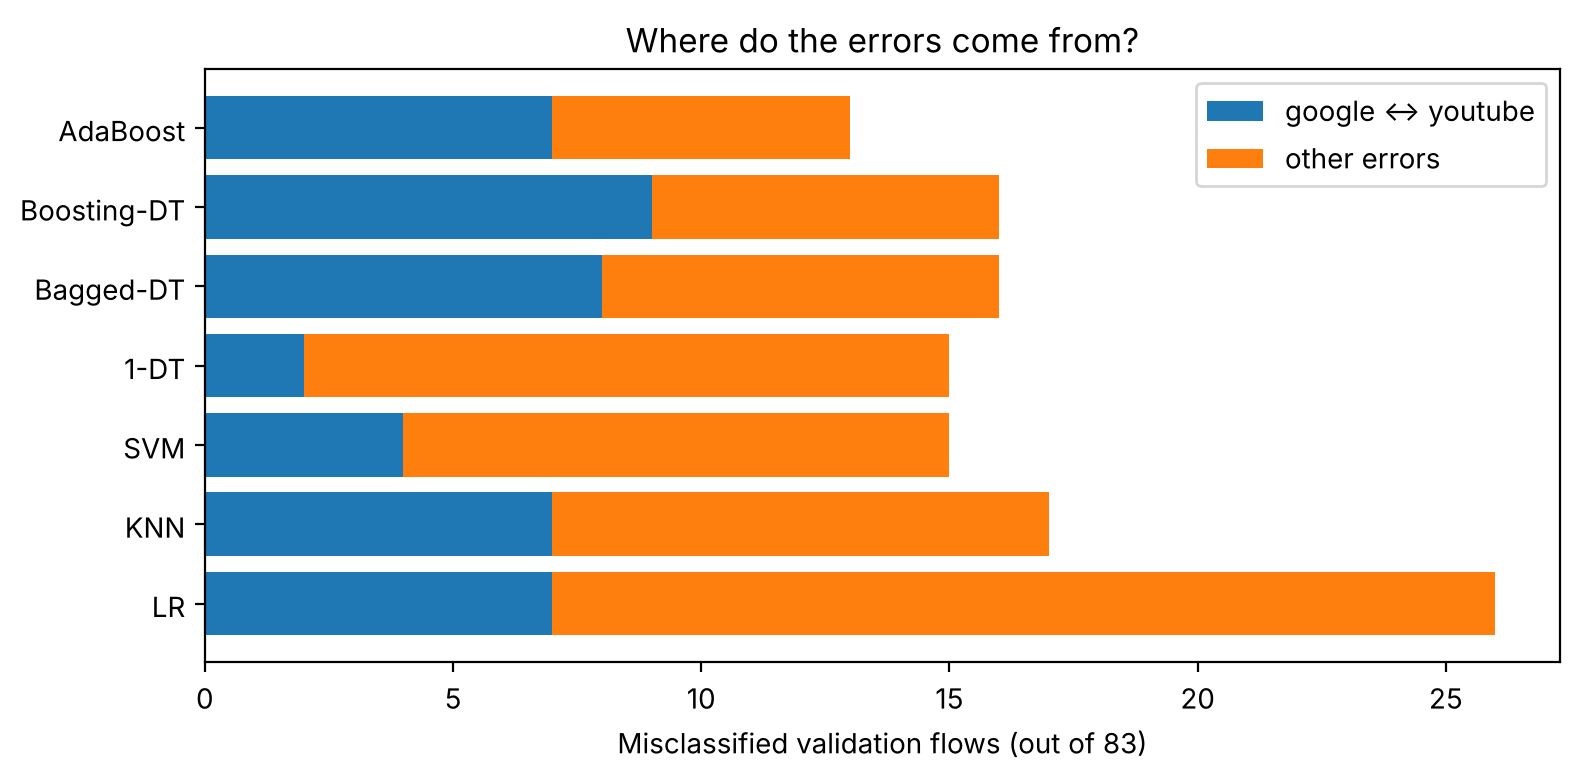

In [10]:
other = swap_df["total_errors"] - swap_df["gy_swaps"]
plt.figure(figsize=(8, 4))
plt.barh(swap_df["Model"], swap_df["gy_swaps"], label="google <-> youtube")
plt.barh(swap_df["Model"], other, left=swap_df["gy_swaps"], label="other errors")
plt.xlabel("Misclassified validation flows (out of 83)")
plt.title("Where do the errors come from?")
plt.legend()
plt.tight_layout()
plt.show()

## 5. Feat-3 = Feat-1 / Feat-2: are the parents still needed?

Two of the derived features are plain ratios:
`down_packet_rate = packet_count_down / duration` and `up_down_pkt_size_ratio = mean_pkt_size_up / mean_pkt_size_down`.
`down_byte_rate_est` is kept in every variant. Everything is log-transformed (carried forward from the skewness
experiments), so for a linear model `log(F1/F2) = log F1 - log F2` is already reachable from the parents.

| Variant | parents kept |
|---|---|
| A_parents | F1, F2 (no derived features = before FE) |
| B_parents+derived | F1, F2, F3 |
| C_derived+numerators | F1, F3 (drop `duration`, `mean_pkt_size_down`) |
| D_derived+denominators | F2, F3 (drop `packet_count_down`, `mean_pkt_size_up`) |
| E_derived_only | F3 only |

Each variant is re-tuned with the same grid as in the model notebooks, so the comparison is not tied to one
hyper-parameter setting.

In [11]:
skewed_features = ['min_iat', 'packet_count_down', 'up_down_byte_ratio', 'bytes_up', 'mean_iat',
                   'duration', 'std_iat', 'max_iat', 'mean_pkt_size_up']
log_features = skewed_features + engineered_features

def preprocess_log(X):
    numeric = X.select_dtypes(include=np.number).columns.tolist()
    categorical = X.select_dtypes(exclude=np.number).columns.tolist()
    log_cols = [c for c in numeric if c in log_features]
    numeric = [c for c in numeric if c not in log_features]
    return ColumnTransformer([('numeric', Pipeline([('scaler', StandardScaler())]), numeric),
                              ('categorical', Pipeline([('onehot', OneHotEncoder(handle_unknown='ignore'))]), categorical),
                              ('log', Pipeline([('log', FunctionTransformer(np.log1p)), ('scaler', StandardScaler())]), log_cols)])

numerators = ['packet_count_down', 'mean_pkt_size_up']
denominators = ['duration', 'mean_pkt_size_down']
variants = {
    'A_parents': selected_features,
    'B_parents+derived': selected_features + engineered_features,
    'C_derived+numerators': [f for f in selected_features if f not in denominators] + engineered_features,
    'D_derived+denominators': [f for f in selected_features if f not in numerators] + engineered_features,
    'E_derived_only': [f for f in selected_features if f not in numerators + denominators] + engineered_features,
}

# same grids as notebooks 01-06
models_and_grids = {
    'LR': (LogisticRegression(max_iter=3000, random_state=random_state),
           {'C': [0.01, 0.1, 1, 10, 100], 'solver': ['lbfgs'], 'class_weight': [None, 'balanced']}),
    'SVM': (SVC(probability=True, random_state=random_state),
            {'C': [0.1, 1, 10, 100], 'kernel': ['linear', 'rbf'], 'gamma': ['scale', 'auto'], 'class_weight': [None, 'balanced']}),
    'KNN': (KNeighborsClassifier(),
            {'n_neighbors': [3, 5, 7, 9, 11, 15, 21], 'weights': ['uniform', 'distance'], 'metric': ['minkowski'], 'p': [1, 2]}),
    '1-DT': (DecisionTreeClassifier(random_state=random_state),
             {'criterion': ['gini', 'entropy'], 'max_depth': [None, 5, 10, 15, 20, 30], 'min_samples_split': [2, 5, 10, 15, 20],
              'min_samples_leaf': [1, 2, 5, 7, 10], 'class_weight': [None, 'balanced']}),
    'Bagged-DT': (BaggingClassifier(estimator=DecisionTreeClassifier(max_depth=15, random_state=random_state), random_state=random_state),
                  {'n_estimators': [10, 25, 50, 100], 'max_samples': [0.5, 0.75, 1.0], 'max_features': [0.5, 0.75, 1.0]}),
    'Boosting-DT': (HistGradientBoostingClassifier(random_state=random_state),
                    {'learning_rate': [0.03, 0.1, 0.2], 'max_iter': [50, 100, 200], 'max_leaf_nodes': [15, 31, 63],
                     'l2_regularization': [0.0, 0.1, 1.0]}),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=random_state)

In [12]:
rows = []
for model_name, (model, grid) in models_and_grids.items():
    for variant, feats in variants.items():
        Xtr, Xte = training_data_fe[feats], validation_data_fe[feats]
        pipe = Pipeline([('preprocess', preprocess_log(Xtr)), ('model', model)])
        search = GridSearchCV(pipe, {'model__' + k: v for k, v in grid.items()}, scoring='f1_macro', cv=cv, n_jobs=-1, refit=True)
        search.fit(Xtr, y_train)
        pred = search.best_estimator_.predict(Xte)
        rows.append({"Model": model_name, "Variant": variant, "n_features": len(feats),
                     "CV_MacroF1": search.best_score_, "Val_MacroF1": f1_score(y_val, pred, average='macro')})
        print(model_name, variant, round(search.best_score_, 4), round(rows[-1]["Val_MacroF1"], 4))

redundancy_df = pd.DataFrame(rows)
redundancy_df.to_csv("derived_feature_redundancy.csv", index=False)

LR A_parents 0.5858 0.6633


LR B_parents+derived 0.5877 0.6507


LR C_derived+numerators 0.5854 0.6551


LR D_derived+denominators 0.5636 0.6772


LR E_derived_only 0.5711 0.6553


/usr/local/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedC

... (106 outputs left out)

Boosting-DT B_parents+derived 0.6681 0.7354


Boosting-DT C_derived+numerators 0.6471 0.6248


Boosting-DT D_derived+denominators 0.7033 0.6858


Boosting-DT E_derived_only 0.6629 0.6173


Val_MacroF1


Model,LR,SVM,KNN,1-DT,Bagged-DT,Boosting-DT,Mean
Variant,,,,,,,
A_parents,0.663,0.704,0.709,0.717,0.733,0.723,0.708
B_parents+derived,0.651,0.695,0.649,0.660,0.698,0.735,0.681
C_derived+numerators,0.655,0.685,0.653,0.620,0.676,0.625,0.652
D_derived+denominators,0.677,0.685,0.651,0.588,0.657,0.686,0.657
E_derived_only,0.655,0.692,0.600,0.591,0.646,0.617,0.634


CV_MacroF1


Model,LR,SVM,KNN,1-DT,Bagged-DT,Boosting-DT,Mean
Variant,,,,,,,
A_parents,0.586,0.627,0.642,0.596,0.670,0.674,0.632
B_parents+derived,0.588,0.624,0.639,0.616,0.670,0.668,0.634
C_derived+numerators,0.585,0.623,0.636,0.591,0.711,0.647,0.632
D_derived+denominators,0.564,0.610,0.663,0.618,0.670,0.703,0.638
E_derived_only,0.571,0.601,0.664,0.615,0.678,0.663,0.632


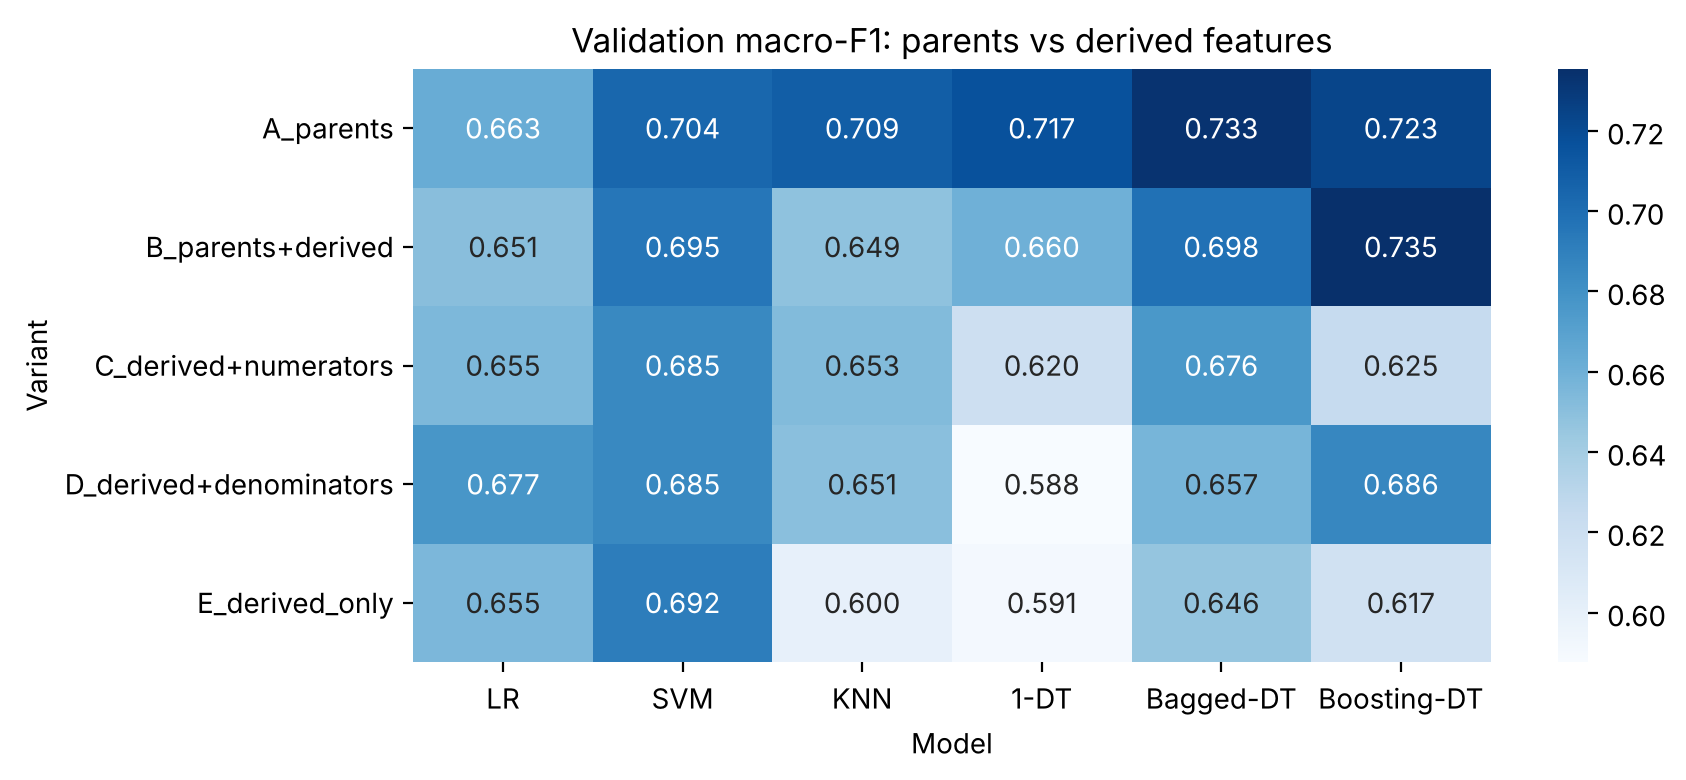

In [13]:
order = list(models_and_grids.keys())
for metric in ["Val_MacroF1", "CV_MacroF1"]:
    pivot = redundancy_df.pivot(index="Variant", columns="Model", values=metric)[order]
    pivot["Mean"] = pivot.mean(axis=1)
    print(metric)
    display(pivot.round(3))

pivot = redundancy_df.pivot(index="Variant", columns="Model", values="Val_MacroF1")[order]
plt.figure(figsize=(9, 4))
sns.heatmap(pivot, annot=True, fmt='.3f', cmap='Blues')
plt.title("Validation macro-F1: parents vs derived features")
plt.tight_layout()
plt.show()

**Reading the table**

- {F1, F3} and {F2, F3} carry exactly the information of {F1, F2} (`F2 = F1 / F3`), and the CV macro-F1 is
  practically the same for A-D. So one parent becomes redundant once the ratio is added, never both.
- Dropping both parents (E) is the worst variant on validation for most models: the ratio alone loses the scale
  (a 0.2 s flow and a 200 s flow can have the same rate).
- LR/SVM/KNN gain nothing from the ratio (after log it is a linear combination of the parents). Trees cannot build
  `F1/F2` with axis-aligned splits, so 1-DT and Boosting are the only ones that pick something up.

## 6. Next steps

- Whichever run above narrows the google→youtube gap, carry that change back into your 8 existing model notebooks:
  swap the fixed 16/9 feature lists for `selected_features + engineered_features`, and either pass
  `model__sample_weight=compute_sample_weight('balanced', y_train)` into `search.fit(...)` inside `report()`, or wrap
  `preprocess_data(...)` and the estimator in an `imblearn.pipeline.Pipeline` with `RandomOverSampler` before handing it to
  `GridSearchCV` (`imblearn`'s `Pipeline` is a drop-in replacement for sklearn's and resamples only the training folds, so CV
  scores stay honest).
- `RandomOverSampler` was used instead of `SMOTE` deliberately: facebook has only 8 training rows total (~6 per CV fold),
  which is already at the edge of what SMOTE's default `k_neighbors=5` needs to interpolate safely. If you want to try SMOTE
  once you have more data, set `k_neighbors=min(5, minority_count - 1)` per class.
- With only 247 training rows across 6 classes, a single train/validation split (as used here) is noisy — if you fold this
  into `GridSearchCV`, consider `RepeatedStratifiedKFold` (e.g. 5 splits × 3 repeats) so the macro-F1 estimate guiding model
  selection isn't dominated by which few youtube/facebook rows happened to land in which fold.
- If the pairwise AUC and boxplots above show that *no* feature here separates google from youtube well even after the
  engineered ones, that's a genuine data ceiling, not a modeling one — the two apps may need a signal this flow-stats-only
  dataset doesn't capture (e.g. SNI/domain name, TLS certificate CN, or IP destination range), and no amount of
  hyperparameter tuning will close that gap.